In [1]:
import os
import torch
from botorch import fit_gpytorch_mll
import botorch_tool
import copy
from botorch.sampling.normal import SobolQMCNormalSampler
from botorch.utils.transforms import unnormalize, normalize, standardize
import numpy as np 
import pickle
from copy import copy 
from scipy.stats import qmc
from matplotlib import pyplot as plt
from botorch.utils.multi_objective.box_decompositions.dominated import DominatedPartitioning
from botorch.utils.multi_objective.pareto import is_non_dominated

torch.set_default_dtype(torch.float64)
tkwargs = {
    "dtype": torch.double,
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu"),
}

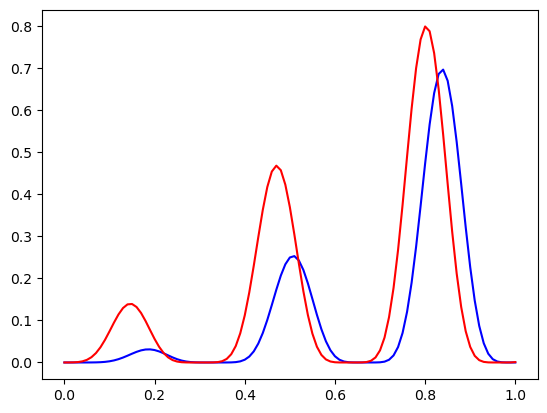

In [2]:
def problem(x):
    f1 = -(x**2 * np.sin(3 * np.pi * x)**6.0) 
    f2 = -(x * np.sin(3 * np.pi * (0.3-x))**6.0) 
    return -torch.concatenate([f1, f2],axis = 1)

x = torch.linspace(0,1,101).reshape(-1,1)
plt.plot(x, problem(x)[:,0], color = "blue")
plt.plot(x, problem(x)[:,1], color = "red")

In [3]:
ININITIAL_SAMPLING_NUM = 4
np.random.seed(42)
torch.manual_seed(42)
LH_sampler = qmc.LatinHypercube(d=1, seed = 42)

#### Bayesian optimization

In [4]:
data_total = []
for repeat in range(16):
    # initial random sampling
    train_observation_x = torch.cat([torch.tensor(LH_sampler.random(n=4))], dim=-1)
    train_observation_y = problem(train_observation_x)
    
    # begin the optimization loop 
    for budget in range(20):
        print(f"{repeat}_{budget} \r")
        # we need to make sure normalize training x to [0,1]
        train_x = train_observation_x
        # standarize train_y
        train_y = standardize(train_observation_y)
        # get the variance of the observations 
        train_y_var = 0.1*torch.rand(train_observation_y.shape)
        
        # get models and train the models
        mll, model = botorch_tool.tools.initialize_heter_noise_model(train_x = train_x, train_obj = train_y, train_obj_var = train_y_var)
        fit_gpytorch_mll(mll)
        # define the boundaries for the optimization problem 
        bounds = torch.stack([torch.zeros(train_x.shape[1]), torch.ones(train_x.shape[1])])
        # get the candidate 
        MC_SAMPLES = 1024
        sampler = SobolQMCNormalSampler(sample_shape=torch.Size([MC_SAMPLES]))
        candidate = botorch_tool.tools.optimize_qnehvi_and_get_observation(
            model = model, 
            train_x = train_x, 
            ref_point = [0,0],
            sampler = sampler)
        train_observation_x = torch.concat((train_observation_x,candidate))
        train_observation_y = torch.concat((train_observation_y,problem(candidate)))
        
    data_total.append(
        [train_observation_x,train_observation_y]
    )
    
with open(f"./qnehvi heter.pkl", 'wb') as fp:
    pickle.dump(data_total, fp)

0_0 


/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-3.7084]), std = tensor([1.2874])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-3.9341]), std = tensor([1.4414])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


0_1 


/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-3.1994]), std = tensor([0.5552])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-4.1632]), std = tensor([1.8573])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


0_2 


/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-3.0483]), std = tensor([0.5523])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-3.2648]), std = tensor([0.5569])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


... (630 outputs left out)

15_18 


/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-3.1574]), std = tensor([0.7110])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-3.5002]), std = tensor([1.2827])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


15_19 


/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-3.1236]), std = tensor([0.6630])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)
/home/xiangan/anaconda3/lib/python3.11/site-packages/botorch/models/utils/assorted.py:202: InputDataWarning: Input data is not standardized (mean = tensor([-3.6858]), std = tensor([1.6501])). Please consider scaling the input to zero mean and unit variance.
  warnings.warn(msg, InputDataWarning)


#### random uniform sampling

In [5]:
data_total = []
np.random.seed(43)
torch.manual_seed(43)

for repeat in range(16):
    # initial random sampling
    train_observation_x = torch.cat([torch.rand(ININITIAL_SAMPLING_NUM, 1)], dim=-1)
    train_observation_y = problem(train_observation_x)
    
    # begin the optimization loop 
    for budget in range(20):
        print(f"{repeat}_{budget} \r")
        # we need to make sure normalize training x to [0,1]
        train_x = train_observation_x
        # standarize train_y
        train_y = standardize(train_observation_y)
        # get the variance of the observations 
        train_y_var = 0.1*torch.rand(train_observation_y.shape)
        candidate = torch.rand(1, 1)
        train_observation_x = torch.concat((train_observation_x,candidate))
        train_observation_y = torch.concat((train_observation_y,problem(candidate)))
        
    data_total.append(
        [train_observation_x,train_observation_y]
    )
    
with open(f"./qnehvi heter_random.pkl", 'wb') as fp:
    pickle.dump(data_total, fp)

0_0 
0_1 
0_2 
0_3 
0_4 
0_5 
0_6 
0_7 
0_8 
0_9 
0_10 
0_11 
0_12 
0_13 
0_14 
0_15 
0_16 
0_17 
0_18 
0_19 
1_0 
1_1 
1_2 
1_3 
1_4 
1_5 
1_6 
1_7 
1_8 
1_9 
1_10 
1_11 
1_12 
1_13 
1_14 
1_15 
1_16 
1_17 
1_18 
1_19 
2_0 
2_1 
2_2 
2_3 
2_4 
2_5 
2_6 
2_7 
2_8 
2_9 
2_10 
2_11 
2_12 
2_13 
2_14 
2_15 
2_16 
2_17 
2_18 
2_19 
3_0 
3_1 
3_2 
3_3 
3_4 
3_5 
3_6 
3_7 
3_8 
3_9 
3_10 
3_11 
3_12 
3_13 
3_14 
3_15 
3_16 
3_17 
3_18 
3_19 
4_0 
4_1 
4_2 
4_3 
4_4 
4_5 
4_6 
4_7 
4_8 
4_9 
4_10 
4_11 
4_12 
4_13 
4_14 
4_15 
4_16 
4_17 
4_18 
4_19 
5_0 
5_1 
5_2 
5_3 
5_4 
5_5 
5_6 
5_7 
5_8 
5_9 
5_10 
5_11 
5_12 
5_13 
5_14 
5_15 
5_16 
5_17 
5_18 
5_19 
6_0 
6_1 
6_2 
6_3 
6_4 
6_5 
6_6 
6_7 
6_8 
6_9 
6_10 
6_11 
6_12 
6_13 
6_14 
6_15 
6_16 
6_17 
6_18 
6_19 
7_0 
7_1 
7_2 
7_3 
7_4 
7_5 
7_6 
7_7 
7_8 
7_9 
7_10 
7_11 
7_12 
7_13 
7_14 
7_15 
7_16 
7_17 
7_18 
7_19 
8_0 
8_1 
8_2 
8_3 
8_4 
8_5 
8_6 
8_7 
8_8 
8_9 
8_10 
8_11 
8_12 
8_13 
8_14 
8_15 
8_16 
8_17 
8_18 
8_19 
9_0 
9_1 


#### plot the results

In [6]:
import pickle

f = open('./qnehvi heter.pkl', 'rb')
data1 = pickle.load(f)  

f = open('./qnehvi heter_random.pkl', 'rb')
data2 = pickle.load(f)  


In [7]:
from botorch.utils.multi_objective.box_decompositions.dominated import (
    DominatedPartitioning,
)
from botorch.utils.multi_objective.pareto import is_non_dominated

hvs_list_total1 = []
for i in range(16):
    train_observation_y = data1[i][1]
    hvs_list = []
    for i in range(len(train_observation_y)-ININITIAL_SAMPLING_NUM):
        bd = DominatedPartitioning(ref_point=torch.tensor([-1,-1]), 
                                   Y = train_observation_y[0:ININITIAL_SAMPLING_NUM+i])
        volume = bd.compute_hypervolume().item()
        hvs_list.append(volume)
    hvs_list_total1.append(hvs_list)
    
hvs_list_total2 = []
for i in range(16):
    train_observation_y = data2[i][1]
    hvs_list = []
    for i in range(len(train_observation_y)-ININITIAL_SAMPLING_NUM):
        bd = DominatedPartitioning(ref_point=torch.tensor([-1,-1]), 
                                   Y = train_observation_y[0:ININITIAL_SAMPLING_NUM+i])
        volume = bd.compute_hypervolume().item()
        hvs_list.append(volume)
    hvs_list_total2.append(hvs_list)

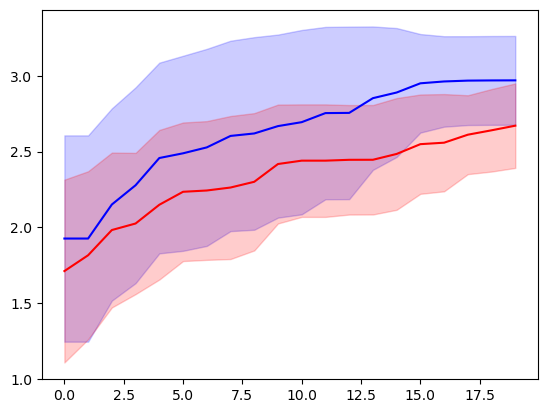

In [8]:
hvs_list_total1 = np.array(hvs_list_total1)
plt.plot(hvs_list_total1.mean(axis = 0), color = "blue", label = "qNEHI")
plt.fill_between(np.arange(len(hvs_list_total1.mean(axis = 0))), 
                 hvs_list_total1.mean(axis = 0) + hvs_list_total1.std(axis = 0), 
                 hvs_list_total1.mean(axis = 0) - hvs_list_total1.std(axis = 0),
                 color='blue', alpha=0.2)

hvs_list_total2 = np.array(hvs_list_total2)
plt.plot(hvs_list_total2.mean(axis = 0), color = "red", label = "random")
plt.fill_between(np.arange(len(hvs_list_total2.mean(axis = 0))), 
                 hvs_list_total2.mean(axis = 0) + hvs_list_total2.std(axis = 0), 
                 hvs_list_total2.mean(axis = 0) - hvs_list_total2.std(axis = 0),
                 color='red', alpha=0.2)

In [16]:
x = torch.tensor(np.linspace(0,1,101))
preidct = model.posterior(x).mean.detach().numpy()
var = model.posterior(x).variance.detach().numpy()

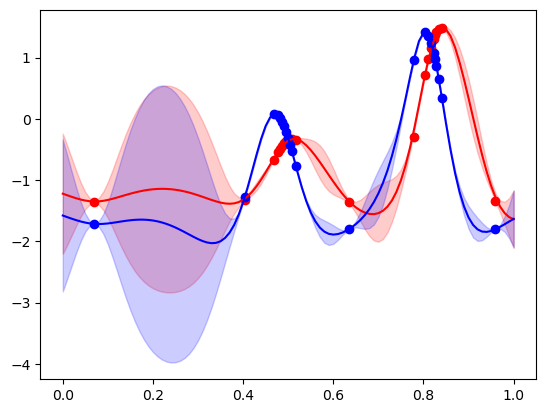

In [40]:
plt.plot(x, preidct[:,0], color = "red", label = "1")
plt.fill_between(x, preidct[:,0] + var[:,0], preidct[:,0] - var[:,0],color='red', alpha=0.2)

plt.plot(x, preidct[:,1], color = "blue", label = "2")
plt.fill_between(x, preidct[:,1] + var[:,1], preidct[:,1] - var[:,1],color='blue', alpha=0.2)

plt.scatter(model.train_inputs[0][0].detach().numpy().flatten(), 
            model.train_targets[0].detach().numpy().flatten(),
           color = "red")

plt.scatter(model.train_inputs[0][0].detach().numpy().flatten(), 
            model.train_targets[1].detach().numpy().flatten(),
           color = "blue")